# Model evaluation: source, baseline transfer and improved transfer

This notebook evaluates the existing trained procedures without fitting or tuning models. The latest **shrunk moment-alignment transfer** is the main comparison against the original 50/50 source/target blend. All other experiments are retained as context.

**Evaluation questions:** How well does the model classify all four age classes? Does it transfer from Madrid to Amsterdam? Are gains consistent across spatial folds, label budgets and sample repetitions? Which classes/locations fail, and how trustworthy are probability estimates?

**What the evidence can establish:** recomputed spatial development cross-validation performance, paired error comparisons and conditional uncertainty for already fitted models. **What it cannot establish:** final-test performance. Only `madrid_train.parquet` and `amsterdam_data.parquet` are available as raw datasets, and both have already been used in development. The final Madrid model has seen all Madrid labels, so evaluating it on Madrid would be an in-sample score; use saved out-of-fold Madrid predictions instead.

**Skills applied:** the directly readable [scikit-learn evaluation instructions](docs/upstream-skills/scikit-learn/references/model_evaluation.md) and [verification-before-completion](docs/upstream-skills/verification-before-completion/SKILL.md). Source/provenance is documented in `docs/upstream-skills/`. No skill installation or runtime dependency changes are needed.


## 1. Verify artifacts and define evaluation units

Load saved predictions, not just reported summary numbers. Hash checks catch accidental differences between models, schemas and recorded results. One independent evaluation record is a **location**; each location has several predictions across training-sample repetitions and different budgets. Those repeated predictions are not additional independent test pixels.

Source-only uses zero Amsterdam labels; few-shot methods use exactly 5/25/50/100/200 labels per class. Spatial folds keep coordinate-key blocks together. Adjacent blocks can still share spatial context, and previously viewed results informed model development.


In [ ]:
from scripts.transfer_adaptation import probabilities, CLASSES
from scripts.moment_transfer import aligned_source_probabilities
from pathlib import Path
import sys
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef,
                             precision_recall_fscore_support, confusion_matrix, log_loss, roc_auc_score, average_precision_score)
from sklearn.preprocessing import label_binarize
from threadpoolctl import threadpool_limits
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'pyproject.toml').is_file() and (p/'data').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Start Jupyter inside this project.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUTPUT = ROOT/'data'/'evaluation'
OUTPUT.mkdir(parents=True, exist_ok=True)
INPUT = ROOT/'data'/'preprocessed_age_labels'
BASE = ROOT/'data'/'baseline'
ALIGN = ROOT/'data'/'transfer_alignment'
SOURCES = {'baseline': BASE, 'leaf_experiment': ROOT /
           'data'/'transfer_improved', 'alignment': ALIGN}
CONFIG = json.loads((BASE/'experiment.json').read_text())
FEATURES = CONFIG['feature_names']
BUDGETS = CONFIG['preprocessing_configuration']['budgets']
N_FOLDS = CONFIG['preprocessing_configuration']['n_folds']
N_REPETITIONS = CONFIG['repetitions']
SEED = 42
BOOTSTRAP_REPEATS = 500
PRIMARY = 'shrunk_moment_alignment'
REFERENCE = 'source_target_blend'
RUN = ['city', 'strategy', 'samples_per_class', 'fold', 'repetition']
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit_learn': sklearn.__version__}


def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''): h.update(block)
    return h.hexdigest()


PREDICTION_PARTS = []
ORIGINAL_METRICS = []
INPUT_HASHES = {}
for name, folder in SOURCES.items():
    manifest = json.loads((folder/'manifest.json').read_text())
    for filename in ['validation_predictions.parquet', 'fold_metrics.csv', 'summary.csv']:
        assert sha256(
            folder/filename) == manifest[filename]['sha256'], f'Mismatched input: {folder/filename}'
        INPUT_HASHES[str((folder/filename).relative_to(ROOT))
                     ] = manifest[filename]['sha256']
    predictions = pd.read_parquet(folder/'validation_predictions.parquet')
    metrics = pd.read_csv(folder/'fold_metrics.csv')
    if 'city' not in predictions:
        predictions['city'] = 'Amsterdam'
    if 'city' not in metrics:
        metrics['city'] = 'Amsterdam'
    PREDICTION_PARTS.append(predictions)
    ORIGINAL_METRICS.append(metrics)
PREDICTIONS = pd.concat(PREDICTION_PARTS, ignore_index=True)
ORIGINAL = pd.concat(ORIGINAL_METRICS, ignore_index=True)
TABLES = {city: pd.read_parquet(
    INPUT/f'{city.lower()}_supervised_features.parquet') for city in ['Madrid', 'Amsterdam']}
for filename in ['madrid_supervised_features.parquet', 'amsterdam_supervised_features.parquet']:
    assert sha256(INPUT/filename) == CONFIG['input_hashes'][filename]
    INPUT_HASHES[str((INPUT/filename).relative_to(ROOT))
                 ] = sha256(INPUT/filename)
raw_paths = list((ROOT/'data').glob('*.parquet'))
print('Available raw datasets:', [p.name for p in raw_paths])
print('Explicitly named test/holdout datasets:',
      [p.name for p in raw_paths if any(s in p.stem.lower() for s in ['test', 'holdout'])])
print('Prediction rows:', f'{len(PREDICTIONS):,}',
      'evaluation runs:', len(ORIGINAL))
print(VERSIONS)

Available raw datasets: ['madrid_train.parquet', 'amsterdam_data.parquet']
Explicitly named test/holdout datasets: []
Prediction rows: 2,517,798 evaluation runs: 465
{'python': '3.14.4', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit_learn': '1.9.1'}


## 2. Check labels, folds, sample budgets and prediction completeness

Join predictions to authoritative location metadata and check that every prediction belongs to its recorded outer validation fold, has the correct age label, and appears exactly once in that run. Confirm that the union of validation locations covers the entire relevant city in each strategy/budget/repetition.

Audit every saved Amsterdam adaptation set for exact per-class counts and exclusion of evaluation locations/blocks. This validates recorded membership and model provenance; it does not prove that arbitrary historical code could never have leaked data. The training notebooks contain the corresponding fitting-time checks.


In [ ]:
assert not PREDICTIONS.duplicated(RUN+['location_id']).any()
assert PREDICTIONS.y_true.isin(CLASSES).all(
) and PREDICTIONS.y_pred.isin(CLASSES).all()
META = pd.concat([t[['location_id', 'city', 'age_class', 'fold', 'spatial_group', 'px_key', 'py_key',
                     'weighted_mean_year', 'n_observed_years', 'no_early_data', 'no_late_data']] for t in TABLES.values()], ignore_index=True)
assert META.location_id.is_unique
META = META.rename(columns={'age_class': 'expected_label',
                   'fold': 'expected_fold', 'city': 'expected_city'})
PREDICTIONS = PREDICTIONS.merge(
    META, on='location_id', how='left', validate='many_to_one')
assert PREDICTIONS.expected_label.notna().all()
assert PREDICTIONS.y_true.eq(PREDICTIONS.expected_label).all()
assert PREDICTIONS.fold.eq(PREDICTIONS.expected_fold).all()
assert PREDICTIONS.city.eq(PREDICTIONS.expected_city).all()
for (city, strategy, n, rep), part in PREDICTIONS.groupby(['city', 'strategy', 'samples_per_class', 'repetition']):
    assert part.location_id.is_unique and len(part) == len(TABLES[city])
    assert set(part.fold) == set(range(N_FOLDS))
MEMBERSHIP = pd.read_csv(BASE/'adaptation_membership.csv')
indexed = TABLES['Amsterdam'].set_index('location_id')
for (fold, n, rep), part in MEMBERSHIP.groupby(['fold', 'samples_per_class', 'repetition']):
    assert part.location_id.is_unique and part.age_class.value_counts().reindex(
        CLASSES).eq(n).all()
    sample = indexed.loc[part.location_id]
    assert sample.fold.ne(fold).all()
    assert sample.age_class.to_list() == part.age_class.to_list()
    assert set(sample.spatial_group).isdisjoint(
        indexed.loc[indexed.fold.eq(fold), 'spatial_group'])
for city, t in TABLES.items():
    assert t.groupby('spatial_group').fold.nunique().max() == 1
print('Labels, full-city validation coverage, all outer folds and all 75 adaptation budgets verified.')

Labels, full-city validation coverage, all outer folds and all 75 adaptation budgets verified.


## 3. Recompute all evaluation metrics from predictions

Macro F1 weights each age class equally. Accuracy measures overall correct classifications; balanced accuracy is mean class recall; MCC summarizes the full confusion structure. Also report class-distance error (0–3) and the fraction of errors spanning at least two classes. Class-distance is ordinal, **not an error in construction years**, since period widths differ.

Compute metrics separately for each outer fold and sampling repetition. Verify macro F1 against the original saved run results before using any summary. Full class-level precision/recall/F1/support and confusion counts are exported for every run.


In [ ]:
metric_rows = []
class_rows = []
confusion_rows = []
for key, part in PREDICTIONS.groupby(RUN, sort=False):
    meta = dict(zip(RUN, key))
    y = part.y_true.to_numpy(dtype=int)
    prediction = part.y_pred.to_numpy(dtype=int)
    distance = np.abs(prediction-y)
    metric_rows.append({**meta, 'n_validation': len(y), 'macro_f1': f1_score(y, prediction, labels=CLASSES, average='macro', zero_division=0),
                        'accuracy': accuracy_score(y, prediction), 'balanced_accuracy': balanced_accuracy_score(y, prediction),
                        'mcc': matthews_corrcoef(y, prediction), 'mean_absolute_class_distance': distance.mean(),
                        'severe_error_fraction': (distance >= 2).mean()})
    p, r, f, s = precision_recall_fscore_support(
        y, prediction, labels=CLASSES, zero_division=0)
    for i, c in enumerate(CLASSES):
        class_rows.append({**meta, 'age_class': int(c),
                          'precision': p[i], 'recall': r[i], 'f1': f[i], 'support': int(s[i])})
    counts = confusion_matrix(y, prediction, labels=CLASSES)
    for i, a in enumerate(CLASSES):
        for j, b in enumerate(CLASSES):
            confusion_rows.append({**meta, 'true_class': int(a), 'predicted_class': int(b),
                                   'count': int(counts[i, j]), 'row_proportion': counts[i, j]/counts[i].sum()})
METRICS = pd.DataFrame(metric_rows)
CLASS_METRICS = pd.DataFrame(class_rows)
CONFUSIONS = pd.DataFrame(confusion_rows)
check = METRICS.merge(ORIGINAL[RUN+['macro_f1']], on=RUN,
                      suffixes=('_recomputed', '_original'), validate='one_to_one')
assert len(check) == len(ORIGINAL)
np.testing.assert_allclose(check.macro_f1_recomputed,
                           check.macro_f1_original, rtol=1e-12, atol=1e-12)
print(f'All {len(METRICS)} macro F1 values independently recomputed and matched saved results.')

All 465 macro F1 values independently recomputed and matched saved results.


## 4. Overall and paired model comparisons

Average repetitions within each fold first; then report means and sample SD across five fold means. Repeated predictions for the same evaluation locations are not treated as independent folds. Sampling variability is shown separately as mean within-fold repetition SD.

Pair the latest alignment with the original blend on identical folds and samples. Count folds with a positive mean change as a stability diagnostic. The average across five budgets is a descriptive proxy for the hackathon's average-score category; peak and 25-label scores summarize its other quantitative categories. These are development proxies, not prize or test-set results.


In [ ]:
GROUP = ['city', 'strategy', 'samples_per_class']
VALUE_COLS = ['macro_f1', 'accuracy', 'balanced_accuracy', 'mcc',
              'mean_absolute_class_distance', 'severe_error_fraction']
FOLD_MEANS = METRICS.groupby(GROUP+['fold'], as_index=False)[VALUE_COLS].mean()
SUMMARY = FOLD_MEANS.groupby(GROUP, as_index=False).agg(
    macro_f1_mean=('macro_f1', 'mean'), macro_f1_fold_sd=('macro_f1', 'std'), accuracy_mean=('accuracy', 'mean'),
    balanced_accuracy_mean=('balanced_accuracy', 'mean'), mcc_mean=('mcc', 'mean'),
    mean_absolute_class_distance=('mean_absolute_class_distance', 'mean'), severe_error_fraction=('severe_error_fraction', 'mean'))
sampling = METRICS.groupby(GROUP+['fold']).macro_f1.std().groupby(
    GROUP).mean().fillna(0).rename('mean_sampling_sd').reset_index()
SUMMARY = SUMMARY.merge(sampling, on=GROUP, validate='one_to_one')
a = FOLD_MEANS.loc[FOLD_MEANS.strategy.eq(PRIMARY), [
    'samples_per_class', 'fold', 'macro_f1']].rename(columns={'macro_f1': 'alignment_f1'})
b = FOLD_MEANS.loc[FOLD_MEANS.strategy.eq(REFERENCE), [
    'samples_per_class', 'fold', 'macro_f1']].rename(columns={'macro_f1': 'baseline_f1'})
PAIRED = a.merge(b, on=['samples_per_class', 'fold'], validate='one_to_one')
PAIRED['delta_f1'] = PAIRED.alignment_f1-PAIRED.baseline_f1
PAIRED_SUMMARY = PAIRED.groupby('samples_per_class', as_index=False).agg(mean_delta_f1=('delta_f1', 'mean'),
                                                                         sd_delta_f1=('delta_f1', 'std'), improved_folds=('delta_f1', lambda s: int(s.gt(0).sum())), n_folds=('fold', 'size'))
CORE = SUMMARY.loc[SUMMARY.strategy.isin(
    ['random_forest', 'dummy_most_frequent', 'source_only', 'target_only', REFERENCE, PRIMARY])]
display(CORE.round(4))
display(PAIRED_SUMMARY.round(4))
CATEGORY_ROWS = []
for strategy in [REFERENCE, PRIMARY]:
    subset = SUMMARY.loc[SUMMARY.strategy.eq(strategy)]
    CATEGORY_ROWS.append({'strategy': strategy, 'mean_F1_across_budgets': subset.macro_f1_mean.mean(),
                          'peak_budget_mean_F1': subset.macro_f1_mean.max(), '25_per_class_mean_F1': subset.loc[subset.samples_per_class.eq(25), 'macro_f1_mean'].iloc[0]})
CATEGORY_PROXY = pd.DataFrame(CATEGORY_ROWS)
display(CATEGORY_PROXY.round(4))

,city,strategy,samples_per_class,macro_f1_mean,macro_f1_fold_sd,accuracy_mean,balanced_accuracy_mean,mcc_mean,mean_absolute_class_distance,severe_error_fraction,mean_sampling_sd
10,Amsterdam,shrunk_moment_alignment,5,0.4824,0.0212,0.5016,0.4937,0.3155,0.6196,0.1068,0.0353
11,Amsterdam,shrunk_moment_alignment,25,0.5519,0.0242,0.5614,0.5657,0.4015,0.5495,0.0985,0.0182
12,Amsterdam,shrunk_moment_alignment,50,0.5906,0.0232,0.5989,0.6044,0.4514,0.4950,0.0833,0.0149
13,Amsterdam,shrunk_moment_alignment,100,0.6132,0.0231,0.6208,0.6293,0.4827,0.4671,0.0776,0.0097
14,Amsterdam,shrunk_moment_alignment,200,0.6295,0.0199,0.6360,0.6456,0.5035,0.4460,0.0723,0.0091
20,Amsterdam,source_only,0,0.3462,0.0152,0.4124,0.3720,0.1900,0.6819,0.0880,0.0000
21,Amsterdam,source_target_blend,5,0.4737,0.0279,0.4970,0.4841,0.3072,0.6166,0.1008,0.0379
22,Amsterdam,source_target_blend,25,0.5494,0.0258,0.5652,0.5559,0.4038,0.5316,0.0863,0.0181
23,Amsterdam,source_target_blend,50,0.5887,0.0254,0.6002,0.5928,0.4509,0.4818,0.0727,0.0139
24,Amsterdam,source_target_blend,100,0.6168,0.0232,0.6256,0.6228,0.4871,0.4499,0.0670,0.0085


,samples_per_class,mean_delta_f1,sd_delta_f1,improved_folds,n_folds
0,5,0.0087,0.0092,5,5
1,25,0.0025,0.0040,4,5
2,50,0.0019,0.0066,3,5
3,100,-0.0035,0.0036,1,5
4,200,-0.0026,0.0054,2,5


,strategy,mean_F1_across_budgets,peak_budget_mean_F1,25_per_class_mean_F1
0,source_target_blend,0.5721,0.6321,0.5494
1,shrunk_moment_alignment,0.5735,0.6295,0.5519


## 5. Class-level performance and confusion matrices

Report class-level metrics for the main methods at 25 labels/class, along with Madrid out-of-fold RF results. For repeated Amsterdam predictions, average within each fold before averaging outer folds; supports are counts per fold, not multiplied by repetitions.

Confusion matrices average row-normalized proportions in the same way. A class with high precision but low recall is often missed; high recall but low precision means the model assigns that class too broadly. City-specific class 1/2 boundaries and mixed-age pixel labels remain interpretation limits.


,city,strategy,samples_per_class,age_class,precision,recall,f1,f1_fold_sd,unique_validation_support
44,Amsterdam,shrunk_moment_alignment,25,1,0.7206,0.5714,0.6353,0.0434,7568.0
45,Amsterdam,shrunk_moment_alignment,25,2,0.5404,0.6151,0.5737,0.0237,8802.0
46,Amsterdam,shrunk_moment_alignment,25,3,0.5602,0.4541,0.4977,0.0446,6745.0
47,Amsterdam,shrunk_moment_alignment,25,4,0.4263,0.6224,0.5008,0.0512,2877.0
88,Amsterdam,source_target_blend,25,1,0.7228,0.5687,0.6337,0.0432,7568.0
89,Amsterdam,source_target_blend,25,2,0.5169,0.6836,0.5872,0.0137,8802.0
90,Amsterdam,source_target_blend,25,3,0.6134,0.4075,0.4847,0.0415,6745.0
91,Amsterdam,source_target_blend,25,4,0.4487,0.5639,0.4919,0.0347,2877.0
128,Madrid,random_forest,0,1,0.6179,0.3970,0.4830,0.0267,13794.0
129,Madrid,random_forest,0,2,0.5602,0.7484,0.6406,0.0133,27152.0


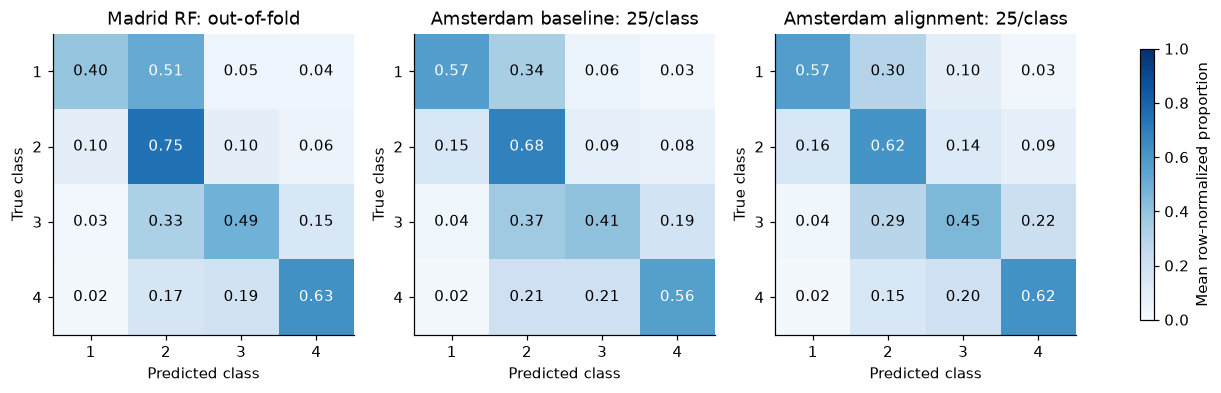

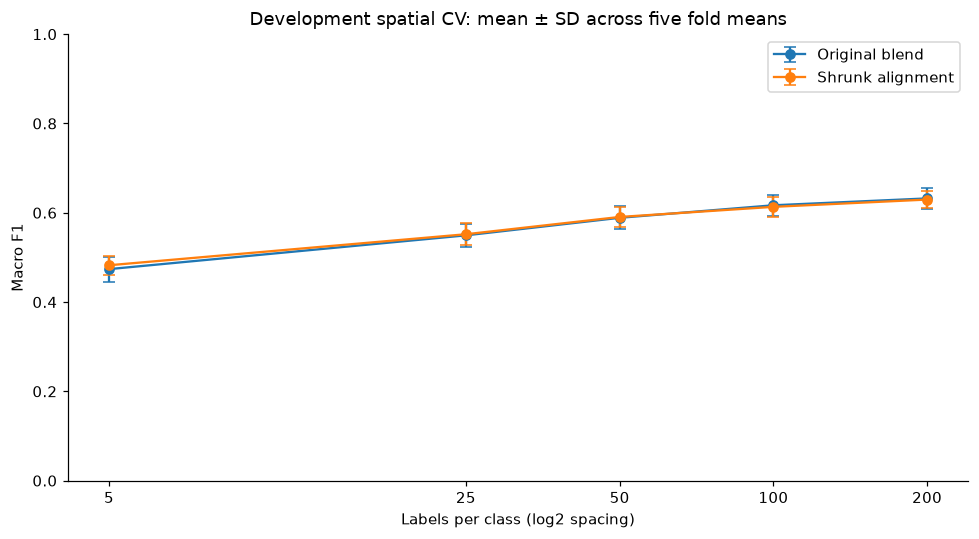

In [ ]:
CLASS_FOLD = CLASS_METRICS.groupby(GROUP+['fold', 'age_class'], as_index=False)[
    ['precision', 'recall', 'f1', 'support']].mean()
CLASS_SUMMARY = CLASS_FOLD.groupby(GROUP+['age_class'], as_index=False).agg(precision=('precision', 'mean'), recall=('recall', 'mean'),
                                                                            f1=('f1', 'mean'), f1_fold_sd=('f1', 'std'), unique_validation_support=('support', 'sum'))
MAIN_CLASSES = CLASS_SUMMARY.loc[(CLASS_SUMMARY.samples_per_class.eq(25) & CLASS_SUMMARY.strategy.isin([REFERENCE, PRIMARY])) |
                                 (CLASS_SUMMARY.city.eq('Madrid') & CLASS_SUMMARY.strategy.eq('random_forest'))]
display(MAIN_CLASSES.round(4))
plt.rcParams.update(
    {'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (city, strategy, n, title) in zip(axes, [('Madrid', 'random_forest', 0, 'Madrid RF: out-of-fold'),
                                                 ('Amsterdam', REFERENCE, 25, 'Amsterdam baseline: 25/class'), ('Amsterdam', PRIMARY, 25, 'Amsterdam alignment: 25/class')]):
    sub = CONFUSIONS.loc[CONFUSIONS.city.eq(city) & CONFUSIONS.strategy.eq(
        strategy) & CONFUSIONS.samples_per_class.eq(n)]
    matrix = sub.groupby(['fold', 'true_class', 'predicted_class']).row_proportion.mean().groupby(
        ['true_class', 'predicted_class']).mean().unstack().reindex(index=CLASSES, columns=CLASSES)
    im = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{matrix.iloc[i, j]:.2f}', ha='center', va='center',
                    color='white' if matrix.iloc[i, j] > .5 else 'black')
    ax.set_xticks(range(4), CLASSES)
    ax.set_yticks(range(4), CLASSES)
    ax.set(title=title, xlabel='Predicted class', ylabel='True class')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.8,
             label='Mean row-normalized proportion')
fig.savefig(OUTPUT/'confusion_matrices.png', bbox_inches='tight')
plt.show()
fig, ax = plt.subplots(figsize=(9, 5))
for strategy, label in [(REFERENCE, 'Original blend'), (PRIMARY, 'Shrunk alignment')]:
    sub = SUMMARY.loc[SUMMARY.strategy.eq(
        strategy)].sort_values('samples_per_class')
    ax.errorbar(np.log2(sub.samples_per_class), sub.macro_f1_mean,
                yerr=sub.macro_f1_fold_sd, marker='o', capsize=4, label=label)
ax.set_xticks(np.log2(BUDGETS), [str(n) for n in BUDGETS])
ax.set(xlabel='Labels per class (log2 spacing)', ylabel='Macro F1', ylim=(
    0, 1), title='Development spatial CV: mean ± SD across five fold means')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT/'learning_curve.png', bbox_inches='tight')
plt.show()

## 6. Conditional spatial block resampling

A simple row bootstrap would incorrectly treat nearby pixels and repeated predictions as independent. Instead, resample **whole spatial blocks within each outer fold**, using the same block weights for both methods and all three repetitions. For each resample, rebuild confusion counts and macro F1, average repetitions within folds, then average folds.

The 2.5th–97.5th percentiles are **conditional block-bootstrap intervals for these fixed fitted models and sampling repetitions**. They do not retrain models, account for adaptation-sample uncertainty, remove overlapping-CV-training dependence, adjust for trying several methods, or establish final-test confidence. Neighboring blocks may also be correlated. Read these alongside fold SD and fold-wise changes; no p-values or significance claims are made.


In [ ]:
def macro_f1_from_counts(counts):
    # Accept any leading dimensions, with true/predicted class as the final axes.
    tp = np.diagonal(counts, axis1=-2, axis2=-1)
    denominator = counts.sum(axis=-1)+counts.sum(axis=-2)
    return np.divide(2*tp, denominator, out=np.zeros_like(tp, dtype=float), where=denominator > 0).mean(axis=-1)


BOOTSTRAP_ROWS = []
BOOTSTRAP_DRAWS = []
for n in BUDGETS:
    rng = np.random.default_rng(np.random.SeedSequence([SEED, n]))
    aggregate = np.zeros((BOOTSTRAP_REPEATS, 2))
    for fold in range(N_FOLDS):
        sub = PREDICTIONS.loc[PREDICTIONS.city.eq('Amsterdam') & PREDICTIONS.samples_per_class.eq(n) &
                              PREDICTIONS.fold.eq(fold) & PREDICTIONS.strategy.isin([REFERENCE, PRIMARY])]
        blocks = sorted(sub.spatial_group.unique())
        block_lookup = {block: i for i, block in enumerate(blocks)}
        counts = np.zeros(
            (len(blocks), 2, N_REPETITIONS, 4, 4), dtype=np.int64)
        block_index = sub.spatial_group.map(block_lookup).to_numpy()
        strategy_index = sub.strategy.map(
            {REFERENCE: 0, PRIMARY: 1}).to_numpy()
        np.add.at(counts, (block_index, strategy_index, sub.repetition.to_numpy(
        ), sub.y_true.to_numpy()-1, sub.y_pred.to_numpy()-1), 1)
        # Match the ordinary fold score before bootstrapping any blocks.
        actual = macro_f1_from_counts(counts.sum(axis=0)).mean(axis=1)
        expected = PAIRED.loc[PAIRED.samples_per_class.eq(
            n) & PAIRED.fold.eq(fold)].iloc[0]
        np.testing.assert_allclose(
            actual, [expected.baseline_f1, expected.alignment_f1])
        weights = rng.multinomial(len(blocks), np.full(
            len(blocks), 1/len(blocks)), size=BOOTSTRAP_REPEATS)
        with threadpool_limits(limits=1):
            resampled = (weights@counts.reshape(len(blocks), -1)
                         ).reshape(BOOTSTRAP_REPEATS, 2, N_REPETITIONS, 4, 4)
        aggregate += macro_f1_from_counts(resampled).mean(axis=-1)/N_FOLDS
    delta = aggregate[:, 1]-aggregate[:, 0]
    lo, hi = np.quantile(delta, [.025, .975])
    BOOTSTRAP_ROWS.append({'samples_per_class': n, 'conditional_delta_low': lo, 'conditional_delta_high': hi,
                           'bootstrap_repeats': BOOTSTRAP_REPEATS})
    BOOTSTRAP_DRAWS.append(pd.DataFrame({'samples_per_class': n, 'draw': np.arange(BOOTSTRAP_REPEATS),
                                         'baseline_f1': aggregate[:, 0], 'alignment_f1': aggregate[:, 1], 'delta_f1': delta}))
BOOTSTRAP_SUMMARY = pd.DataFrame(BOOTSTRAP_ROWS)
BOOTSTRAP_SAMPLES = pd.concat(BOOTSTRAP_DRAWS, ignore_index=True)
PAIRED_SUMMARY = PAIRED_SUMMARY.merge(
    BOOTSTRAP_SUMMARY, on='samples_per_class', validate='one_to_one')
display(PAIRED_SUMMARY.round(4))

,samples_per_class,mean_delta_f1,sd_delta_f1,improved_folds,n_folds,conditional_delta_low,conditional_delta_high,bootstrap_repeats
0,5,0.0087,0.0092,5,5,0.0032,0.0141,500
1,25,0.0025,0.0040,4,5,-0.0050,0.0090,500
2,50,0.0019,0.0066,3,5,-0.0027,0.0075,500
3,100,-0.0035,0.0036,1,5,-0.0082,0.0016,500
4,200,-0.0026,0.0054,2,5,-0.0077,0.0031,500


## 7. Error slices: coverage, observation history and label boundaries

Evaluate difficult subsets at 25 labels/class for baseline and alignment. Join building coverage from raw records for diagnosis only; construction years and coverage do not become predictors. Use median coverage per location so long time series do not count extra.

For each subset, report location count, represented classes, accuracy and severe error rate. Subset macro F1 is only shown when all four classes are present. Average metrics within each run and then within fold/repetition hierarchy; a small or shifted subset is not comparable to the whole city without considering class mix. These are exploratory error diagnostics, not new model-selection inputs.


,strategy,slice_kind,slice,unique_locations,minimum_classes_in_fold,accuracy,macro_f1,severe_error_fraction
0,shrunk_moment_alignment,boundary_slice,>2 years from a class boundary,22486.0,4.0,0.5726,0.5592,0.0982
1,shrunk_moment_alignment,boundary_slice,≤2 years from a class boundary,3506.0,4.0,0.4835,0.4194,0.0993
2,shrunk_moment_alignment,coverage_slice,coverage 35–65%,10147.0,4.0,0.5942,0.5732,0.0829
3,shrunk_moment_alignment,coverage_slice,coverage >65%,3695.0,4.0,0.4643,0.4499,0.1407
4,shrunk_moment_alignment,coverage_slice,coverage ≤35%,12150.0,4.0,0.5650,0.5441,0.0981
5,shrunk_moment_alignment,history_slice,31–39 observed years,4657.0,4.0,0.5232,0.4871,0.1304
6,shrunk_moment_alignment,history_slice,≤30 observed years,492.0,4.0,0.5146,0.3571,0.1020
7,shrunk_moment_alignment,history_slice,≥40 observed years,20843.0,4.0,0.5712,0.5586,0.0914
8,source_target_blend,boundary_slice,>2 years from a class boundary,22486.0,4.0,0.5764,0.5568,0.0845
9,source_target_blend,boundary_slice,≤2 years from a class boundary,3506.0,4.0,0.4876,0.4148,0.0975


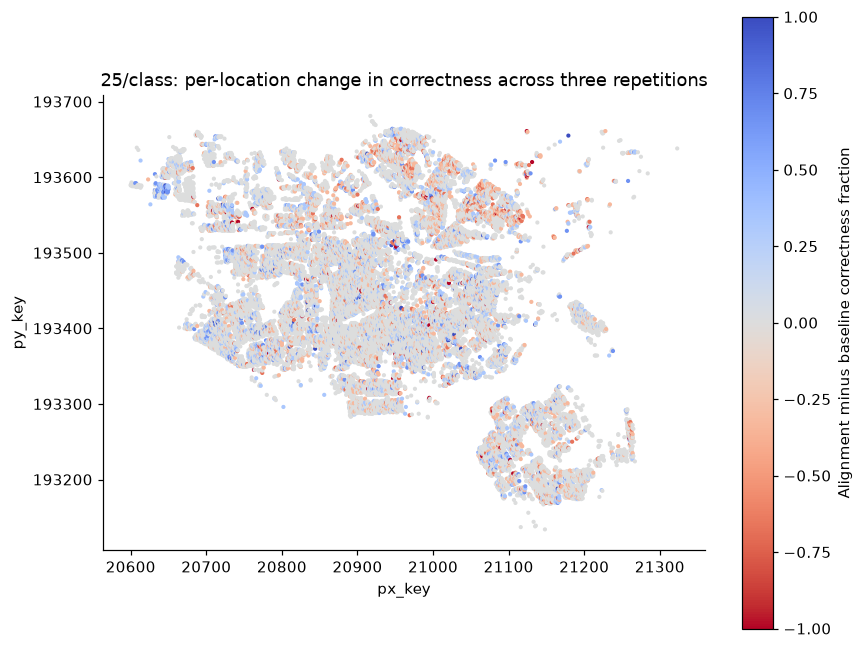

In [ ]:
raw_path = ROOT/'data'/'amsterdam_data.parquet'
assert sha256(
    raw_path) == CONFIG['preprocessing_configuration']['inputs']['Amsterdam']['sha256']
INPUT_HASHES[str(raw_path.relative_to(ROOT))] = sha256(raw_path)
raw = pd.read_parquet(ROOT/'data'/'amsterdam_data.parquet',
                      columns=['city', 'px_key', 'py_key', 'coverage'])
coverage = raw.groupby(['city', 'px_key', 'py_key']
                       ).coverage.median().reset_index()
loc = TABLES['Amsterdam'].merge(
    coverage, on=['city', 'px_key', 'py_key'], validate='one_to_one')
event = CONFIG['preprocessing_configuration']['class_events']['Amsterdam']
loc['boundary_distance_years'] = np.min(np.abs(loc.weighted_mean_year.to_numpy()[
                                        :, None]-np.array([event, 1984, 2004])[None, :]), axis=1)
loc['coverage_slice'] = pd.cut(loc.coverage, [0, .35, .65, 1.], labels=[
                               'coverage ≤35%', 'coverage 35–65%', 'coverage >65%'], include_lowest=True).astype(str)
loc['history_slice'] = pd.cut(loc.n_observed_years, [0, 30, 39, 100], labels=[
                              '≤30 observed years', '31–39 observed years', '≥40 observed years'], include_lowest=True).astype(str)
loc['boundary_slice'] = np.where(loc.boundary_distance_years <= 2,
                                 '≤2 years from a class boundary', '>2 years from a class boundary')
error_predictions = PREDICTIONS.loc[PREDICTIONS.city.eq(
    'Amsterdam') & PREDICTIONS.samples_per_class.eq(25) & PREDICTIONS.strategy.isin([REFERENCE, PRIMARY])]
error_predictions = error_predictions.merge(
    loc[['location_id', 'coverage_slice', 'history_slice', 'boundary_slice']], on='location_id', validate='many_to_one')
slice_rows = []
for slice_kind in ['coverage_slice', 'history_slice', 'boundary_slice']:
    for key, part in error_predictions.groupby(['strategy', 'fold', 'repetition', slice_kind]):
        strategy, fold, rep, label = key
        y = part.y_true.to_numpy()
        pred = part.y_pred.to_numpy()
        represented = len(np.unique(y))
        slice_rows.append({'strategy': strategy, 'fold': fold, 'repetition': rep, 'slice_kind': slice_kind, 'slice': label,
                           'n_locations': part.location_id.nunique(), 'n_classes': represented, 'accuracy': accuracy_score(y, pred),
                           'macro_f1': f1_score(y, pred, labels=CLASSES, average='macro', zero_division=0) if represented == 4 else np.nan,
                           'severe_error_fraction': (np.abs(y-pred) >= 2).mean()})
SLICE_METRICS = pd.DataFrame(slice_rows)
SLICE_FOLD = SLICE_METRICS.groupby(['strategy', 'slice_kind', 'slice', 'fold'], as_index=False)[
    ['n_locations', 'n_classes', 'accuracy', 'macro_f1', 'severe_error_fraction']].mean()
SLICE_SUMMARY = SLICE_FOLD.groupby(['strategy', 'slice_kind', 'slice'], as_index=False).agg(unique_locations=('n_locations', 'sum'),
                                                                                            minimum_classes_in_fold=('n_classes', 'min'), accuracy=('accuracy', 'mean'), macro_f1=('macro_f1', 'mean'), severe_error_fraction=('severe_error_fraction', 'mean'))
SLICE_SUMMARY.loc[SLICE_SUMMARY.minimum_classes_in_fold.lt(
    4), 'macro_f1'] = np.nan
display(SLICE_SUMMARY.round(4))
# A spatial error map averages repeated predictions for each location; never multiplies location counts.
spatial = error_predictions.assign(correct=lambda x: x.y_true.eq(x.y_pred).astype(
    float)).groupby(['location_id', 'strategy']).correct.mean().unstack()
spatial['accuracy_change'] = spatial[PRIMARY]-spatial[REFERENCE]
spatial = spatial.reset_index().merge(
    loc[['location_id', 'px_key', 'py_key']], on='location_id', validate='one_to_one')
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.scatter(spatial.px_key, spatial.py_key, c=spatial.accuracy_change,
                s=3, vmin=-1, vmax=1, cmap='coolwarm_r', rasterized=True)
ax.set(xlabel='px_key', ylabel='py_key',
       title='25/class: per-location change in correctness across three repetitions', aspect='equal')
fig.colorbar(im, ax=ax, label='Alignment minus baseline correctness fraction')
fig.tight_layout()
fig.savefig(OUTPUT/'spatial_error_change.png', bbox_inches='tight')
plt.show()

## 8. Fresh saved-model inference and probability quality

Saved example models exclude Amsterdam **fold 0, repetition 0**. Re-run those models and compare predictions with recorded out-of-fold results before computing probability diagnostics. Baseline and alignment are compared on exactly the same locations. The source-only model uses no Amsterdam labels.

Report log loss, multiclass Brier score (mean sum of four squared probability errors), macro one-vs-rest ROC AUC, macro average precision and top-label ECE in ten fixed confidence bins. Lower log loss/Brier/ECE is better; higher AUC/AP is better. ECE depends on binning and sample size, and none of these forests are claimed to be calibrated.

**Scope limitation:** probability metrics are for one saved fold/repetition only, not five-fold means. The remaining saved cross-validation predictions contain hard labels only, so complete CV calibration cannot be recovered without additional training/inference artifacts. No calibration transformation or confidence threshold is fitted here.


,strategy,samples_per_class,scope,n_validation,log_loss,multiclass_brier,macro_ovr_auc,macro_average_precision,ece_10_bins
0,source_only,0,Amsterdam fold 0 / repetition 0,5197,1.1918,0.6730,0.7198,0.4326,0.0636
1,source_target_blend,5,Amsterdam fold 0 / repetition 0,5197,1.1662,0.6444,0.7360,0.4835,0.0566
2,shrunk_moment_alignment,5,Amsterdam fold 0 / repetition 0,5197,1.1651,0.6429,0.7356,0.4794,0.0599
3,source_target_blend,25,Amsterdam fold 0 / repetition 0,5197,1.0546,0.5826,0.8092,0.5669,0.0891
4,shrunk_moment_alignment,25,Amsterdam fold 0 / repetition 0,5197,1.0629,0.5843,0.8059,0.5525,0.0980
5,source_target_blend,50,Amsterdam fold 0 / repetition 0,5197,1.0097,0.5542,0.8319,0.6237,0.1203
6,shrunk_moment_alignment,50,Amsterdam fold 0 / repetition 0,5197,1.0132,0.5529,0.8335,0.6173,0.1284
7,source_target_blend,100,Amsterdam fold 0 / repetition 0,5197,0.9809,0.5383,0.8442,0.6482,0.1345
8,shrunk_moment_alignment,100,Amsterdam fold 0 / repetition 0,5197,0.9856,0.5396,0.8454,0.6401,0.1321
9,source_target_blend,200,Amsterdam fold 0 / repetition 0,5197,0.9809,0.5396,0.8439,0.6483,0.1309


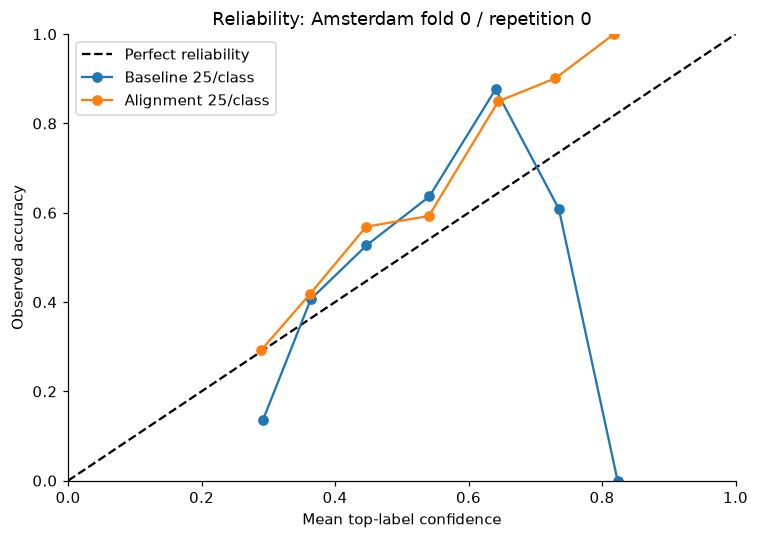

Fresh predictions from the source and ten saved adaptation models match recorded results.


In [ ]:
SOURCE = joblib.load(BASE/'madrid_source_model.joblib')
source_manifest = json.loads((BASE/'manifest.json').read_text())
INPUT_HASHES[str((BASE/'madrid_source_model.joblib').relative_to(ROOT))
             ] = sha256(BASE/'madrid_source_model.joblib')
assert sha256(
    BASE/'madrid_source_model.joblib') == source_manifest['madrid_source_model.joblib']['sha256']
validation = TABLES['Amsterdam'].loc[lambda x:x.fold.eq(0)]
y = validation.age_class.to_numpy(dtype=int)
onehot = label_binarize(y, classes=CLASSES)
source_prob = probabilities(SOURCE, validation[FEATURES])
probability_rows = []
reliability_rows = []
probability_parts = []


def evaluate_probability(strategy, n, proba):
    assert np.isfinite(proba).all() and np.allclose(proba.sum(axis=1), 1)
    prediction = CLASSES[proba.argmax(axis=1)]
    expected = PREDICTIONS.loc[PREDICTIONS.city.eq('Amsterdam') & PREDICTIONS.strategy.eq(strategy) &
                               PREDICTIONS.samples_per_class.eq(n) & PREDICTIONS.fold.eq(0) & PREDICTIONS.repetition.eq(0)].set_index('location_id')
    np.testing.assert_array_equal(
        prediction, expected.loc[validation.location_id, 'y_pred'].to_numpy())
    confidence = proba.max(axis=1)
    correct = prediction == y
    bins = np.minimum((confidence*10).astype(int), 9)
    ece = 0.
    for k in range(10):
        mask = bins == k
        if mask.any():
            mean_confidence = confidence[mask].mean()
            bin_accuracy = correct[mask].mean()
            ece += mask.mean()*abs(bin_accuracy-mean_confidence)
            reliability_rows.append({'strategy': strategy, 'samples_per_class': n, 'bin': k, 'count': int(mask.sum()),
                                     'mean_confidence': mean_confidence, 'accuracy': bin_accuracy})
    probability_rows.append({'strategy': strategy, 'samples_per_class': n, 'scope': 'Amsterdam fold 0 / repetition 0',
                             'n_validation': len(y), 'log_loss': log_loss(y, proba, labels=CLASSES),
                             'multiclass_brier': np.mean(np.sum((proba-onehot)**2, axis=1)),
                             'macro_ovr_auc': roc_auc_score(y, proba, labels=CLASSES, average='macro', multi_class='ovr'),
                             'macro_average_precision': average_precision_score(onehot, proba, average='macro'), 'ece_10_bins': ece})
    part = validation[['location_id', 'age_class']].rename(
        columns={'age_class': 'y_true'}).copy()
    part['strategy'] = strategy
    part['samples_per_class'] = n
    for j, c in enumerate(CLASSES):
        part[f'p_class_{c}'] = proba[:, j]
    probability_parts.append(part)


evaluate_probability('source_only', 0, source_prob)
for n in BUDGETS:
    baseline_path = BASE/f'amsterdam_fold0_n{n}_rep0.joblib'
    assert sha256(
        baseline_path) == source_manifest[baseline_path.name]['sha256']
    INPUT_HASHES[str(baseline_path.relative_to(ROOT))] = sha256(baseline_path)
    baseline_bundle = joblib.load(baseline_path)
    expected_ids = set(MEMBERSHIP.loc[MEMBERSHIP.fold.eq(
        0) & MEMBERSHIP.samples_per_class.eq(n) & MEMBERSHIP.repetition.eq(0), 'location_id'])
    assert set(baseline_bundle['adaptation_location_ids']) == expected_ids
    target_prob = probabilities(
        baseline_bundle['target_pipeline'], validation[FEATURES])
    evaluate_probability(REFERENCE, n, baseline_bundle['source_weight']*source_prob+(
        1-baseline_bundle['source_weight'])*target_prob)
    alignment_path = ALIGN/f'shrunk_moment_alignment_fold0_n{n}.joblib'
    alignment_manifest = json.loads((ALIGN/'manifest.json').read_text())
    assert sha256(
        alignment_path) == alignment_manifest[alignment_path.name]['sha256']
    INPUT_HASHES[str(alignment_path.relative_to(ROOT))
                 ] = sha256(alignment_path)
    alignment_bundle = joblib.load(alignment_path)
    assert set(alignment_bundle['adaptation_location_ids']) == expected_ids
    assert expected_ids.isdisjoint(validation.location_id)
    aligned_prob = aligned_source_probabilities(SOURCE, validation[FEATURES], alignment_bundle['source_reference'],
                                                alignment_bundle['target_moments'], alignment_bundle['prior_count'])
    target_prob = probabilities(
        alignment_bundle['target_pipeline'], validation[FEATURES])
    evaluate_probability(PRIMARY, n, .5*aligned_prob+.5*target_prob)
PROBABILITY_METRICS = pd.DataFrame(probability_rows)
RELIABILITY = pd.DataFrame(reliability_rows)
PROBABILITIES = pd.concat(probability_parts, ignore_index=True)
display(PROBABILITY_METRICS.round(4))
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], 'k--', label='Perfect reliability')
for strategy, label in [(REFERENCE, 'Baseline 25/class'), (PRIMARY, 'Alignment 25/class')]:
    sub = RELIABILITY.loc[RELIABILITY.strategy.eq(
        strategy) & RELIABILITY.samples_per_class.eq(25)]
    ax.plot(sub.mean_confidence, sub.accuracy, marker='o', label=label)
ax.set(xlabel='Mean top-label confidence', ylabel='Observed accuracy',
       xlim=(0, 1), ylim=(0, 1), title='Reliability: Amsterdam fold 0 / repetition 0')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT/'reliability_fold0.png', bbox_inches='tight')
plt.show()
print('Fresh predictions from the source and ten saved adaptation models match recorded results.')

## 9. Export the evaluation and evidence-backed conclusions

Export recomputed metrics, paired fold changes, conditional bootstrap draws, class/confusion results, error slices and fold-0 probability diagnostics. The report explicitly separates five-fold hard-label evaluation from one-fold probability evaluation and makes no unseen-test claim.

Keep the original baseline as a comparator: improved transfer at a small budget is not evidence of universal improvement. Class-level weaknesses, uncertain labels and spatial dependence should guide future development, with model selection confined to training/inner folds and final confirmation reserved for organizer-held-out data.


In [ ]:
EXPORTS = {'recomputed_run_metrics': METRICS, 'model_summary': SUMMARY, 'fold_mean_metrics': FOLD_MEANS,
           'paired_fold_differences': PAIRED, 'paired_comparison': PAIRED_SUMMARY, 'category_proxies': CATEGORY_PROXY,
           'class_metrics': CLASS_METRICS, 'class_summary': CLASS_SUMMARY, 'confusion_matrices': CONFUSIONS,
           'conditional_block_bootstrap_draws': BOOTSTRAP_SAMPLES, 'error_slice_metrics': SLICE_METRICS,
           'error_slice_summary': SLICE_SUMMARY, 'probability_metrics_fold0': PROBABILITY_METRICS, 'reliability_bins_fold0': RELIABILITY}
for name, frame in EXPORTS.items():
    frame.to_csv(OUTPUT/f'{name}.csv', index=False)
PROBABILITIES.to_parquet(
    OUTPUT/'probability_predictions_fold0.parquet', index=False)
provenance = {'input_hashes': INPUT_HASHES, 'versions': VERSIONS, 'bootstrap_repeats': BOOTSTRAP_REPEATS, 'seed': SEED,
              'primary_strategy': PRIMARY, 'reference_strategy': REFERENCE, 'probability_scope': 'fold 0, repetition 0 only',
              'no_models_fitted': True, 'independent_test_available': False, 'organizer_test_sets_used': False,
              'outer_results_previously_viewed': True, 'recomputed_run_count': len(METRICS), 'prediction_row_count': len(PREDICTIONS),
              'bootstrap_scope': 'conditional on saved fitted models and fixed sampling repetitions; not a selection-adjusted generalization CI'}
(OUTPUT/'evaluation.json').write_text(json.dumps(provenance, indent=2)+'\n')


def get(strategy, n=0, city='Amsterdam'):
    return SUMMARY.loc[SUMMARY.city.eq(city) & SUMMARY.strategy.eq(strategy) & SUMMARY.samples_per_class.eq(n)].iloc[0]


def fmt(row): return f'{row.macro_f1_mean:.4f} ± {row.macro_f1_fold_sd:.4f}'


rf = get('random_forest', city='Madrid')
dummy = get('dummy_most_frequent', city='Madrid')
source = get('source_only')
lines = ['# Model evaluation report', '',
         f'Madrid random forest: **macro F1 {fmt(rf)}**, accuracy {rf.accuracy_mean:.4f}, balanced accuracy {rf.balanced_accuracy_mean:.4f}, MCC {rf.mcc_mean:.4f}. Most-frequent dummy macro F1: {fmt(dummy)}.',
         f'Amsterdam source-only (zero local labels): **macro F1 {fmt(source)}**.', '',
         'These are spatial development cross-validation results, independently recomputed from saved predictions. No untouched test set is available locally. Final Madrid training-set predictions are not used as evaluation.', '',
         '| Labels/class | Original blend macro F1 | Shrunk alignment macro F1 | Paired Δ F1 | Improved folds |',
         '| ---: | ---: | ---: | ---: | ---: |']
for n in BUDGETS:
    a = get(REFERENCE, n)
    b = get(PRIMARY, n)
    paired = PAIRED_SUMMARY.loc[PAIRED_SUMMARY.samples_per_class.eq(n)].iloc[0]
    lines.append(
        f'| {n} | {fmt(a)} | {fmt(b)} | {paired.mean_delta_f1:+.4f} | {int(paired.improved_folds)}/{int(paired.n_folds)} |')
lines += ['', 'Means first average three sampling repetitions within each fold; SD is across five fold means. It is not a confidence interval. Five budgets are all reported; no retrospective hybrid model is scored.', '',
          '## Class-level results at 25 labels/class', '',
          '| Class | Baseline precision | Baseline recall | Baseline F1 | Alignment precision | Alignment recall | Alignment F1 |',
          '| ---: | ---: | ---: | ---: | ---: | ---: | ---: |']
for c in CLASSES:
    a = CLASS_SUMMARY.loc[CLASS_SUMMARY.strategy.eq(
        REFERENCE) & CLASS_SUMMARY.samples_per_class.eq(25) & CLASS_SUMMARY.age_class.eq(c)].iloc[0]
    b = CLASS_SUMMARY.loc[CLASS_SUMMARY.strategy.eq(
        PRIMARY) & CLASS_SUMMARY.samples_per_class.eq(25) & CLASS_SUMMARY.age_class.eq(c)].iloc[0]
    lines.append(
        f'| {c} | {a.precision:.4f} | {a.recall:.4f} | {a.f1:.4f} | {b.precision:.4f} | {b.recall:.4f} | {b.f1:.4f} |')
baseline25 = get(REFERENCE, 25)
alignment25 = get(PRIMARY, 25)
paired25 = PAIRED_SUMMARY.loc[PAIRED_SUMMARY.samples_per_class.eq(25)].iloc[0]
pb25 = PROBABILITY_METRICS.loc[PROBABILITY_METRICS.strategy.eq(
    REFERENCE) & PROBABILITY_METRICS.samples_per_class.eq(25)].iloc[0]
pa25 = PROBABILITY_METRICS.loc[PROBABILITY_METRICS.strategy.eq(
    PRIMARY) & PROBABILITY_METRICS.samples_per_class.eq(25)].iloc[0]
weak = CLASS_SUMMARY.loc[CLASS_SUMMARY.strategy.eq(
    PRIMARY) & CLASS_SUMMARY.samples_per_class.eq(25)].sort_values('f1').iloc[0]
lines += ['', f'Lowest mean class F1 for alignment at 25/class: class {int(weak.age_class)} ({weak.f1:.4f}); inspect its precision/recall tradeoff and confusion rows before proposing changes.', '',
          '## Score trade-offs at 25 labels/class', '',
          f'Compared with the original blend, alignment changes accuracy from {baseline25.accuracy_mean:.2%} to {alignment25.accuracy_mean:.2%}, balanced accuracy from {baseline25.balanced_accuracy_mean:.2%} to {alignment25.balanced_accuracy_mean:.2%}, and MCC from {baseline25.mcc_mean:.4f} to {alignment25.mcc_mean:.4f}. Errors spanning at least two classes rise from {baseline25.severe_error_fraction:.2%} to {alignment25.severe_error_fraction:.2%}. The small macro-F1 gain therefore does not imply better performance on every criterion.', '',
          '## Stability and probability quality', '',
          f'- At 25/class, the conditional block-resampling interval for paired F1 change is [{paired25.conditional_delta_low:+.4f}, {paired25.conditional_delta_high:+.4f}], including zero. This is a limited fixed-model uncertainty diagnostic, not evidence of a confirmed generalization gain.',
          f'- On fold 0 / repetition 0 at 25/class, baseline versus alignment log loss is {pb25.log_loss:.4f} versus {pa25.log_loss:.4f}, Brier is {pb25.multiclass_brier:.4f} versus {pa25.multiclass_brier:.4f}, and ten-bin ECE is {pb25.ece_10_bins:.4f} versus {pa25.ece_10_bins:.4f}. Probability quality does not improve on these criteria in this saved example fold.',

          '- Paired spatial-block bootstrap intervals and draws are exported. They are conditional on the saved fitted models and fixed adaptation samples. They do not include full retraining uncertainty, cross-validation dependence or correction for trying several methods, and are not independent-test confidence intervals.',
          '- Probabilities were freshly generated from the saved source model and ten saved baseline/alignment models. All predictions matched recorded results. Log loss, multiclass Brier, macro OVR AUC, macro average precision and ten-bin ECE are exported for Amsterdam fold 0 / repetition 0 only; they are not five-fold averages.',
          '- Reliability diagrams show probability behavior without fitting calibration on evaluation data. Probability metrics from one fold cannot establish calibration throughout the city.', '',
          '## Evaluation limits and practical conclusion', '',
          '- The shrunk alignment shows modest development gains at 5, 25 and 50 labels/class, and regressions at 100 and 200. The original baseline remains the reference; there is no demonstrated universal transfer improvement.',
          '- The development outer-fold results have been viewed repeatedly and informed experiment design. Neither the apparent best method nor the best budget has an unbiased final-test score here.',
          '- Spatial blocks stay separate, but touching blocks may remain correlated. Current class 1/2 historical boundaries and endpoint conventions require organizer confirmation, and area-weighted construction-year labels can be ambiguous in mixed-age pixels.',
          '- Error slices by building coverage, observation history and proximity to class boundaries are exploratory and retain their counts/class coverage. Class-distance error is ordinal, not construction-year error.',
          '- Reserve organizer test data for a frozen final procedure. More elaborate calibration, feature selection or blend-weight tuning must use training/inner folds, not these evaluation labels.', '',
          '## Reproduction and artifacts', '',
          'Run `evaluation.ipynb` after preprocessing, baseline and transfer experiments. It fits no models and does not alter prior models or predictions. Detailed tables, figures, probability predictions, input hashes and the evaluation manifest are in `data/evaluation/`.', '',
          f'Verification: {len(METRICS)} evaluation-run scores recomputed from {len(PREDICTIONS):,} saved prediction rows; full city/location coverage, label agreement, folds and all 75 adaptation budgets checked. All probability predictions from saved models reproduce recorded labels.', '',
          '## Skills and software', '',
          'Applied the downloaded scikit-learn model-evaluation and verification-before-completion skills. They are directly readable instruction copies in `docs/upstream-skills/`, not registered `.agents` installations. No runtime dependencies changed.',
          'Kassis, T., Agarwal, V., He, Y., Patel, D., & Brueckner, A. M. (2026). *Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents*. https://doi.org/10.48550/arXiv.2609.00065.']
(ROOT/'docs'/'MODEL_EVALUATION.md').write_text('\n'.join(lines)+'\n')
pd.testing.assert_frame_equal(PROBABILITIES, pd.read_parquet(
    OUTPUT/'probability_predictions_fold0.parquet'))
pd.testing.assert_frame_equal(SUMMARY, pd.read_csv(
    OUTPUT/'model_summary.csv'), check_exact=False, rtol=1e-12, atol=1e-12)
manifest = {p.name: {'bytes': p.stat().st_size, 'sha256': sha256(p)} for p in sorted(
    OUTPUT.iterdir()) if p.is_file() and p.name != 'manifest.json'}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest, indent=2)+'\n')
print('Evaluation exports and round-trip checks passed.')
print('Report:', ROOT/'docs'/'MODEL_EVALUATION.md')

Evaluation exports and round-trip checks passed.
Report: /home/mirado/hack4dev/Building_Age_Classification/docs/MODEL_EVALUATION.md
